# Paper Example 3: River Water from a Groundwater Flow Model

This notebook walks through Example 3 of the PyTracerLab paper. The reference system
is a groundwater flow model (MODFLOW 6; details in the Supplementary Material of the
paper). River water is a mixture of groundwater (water that entered the system as
recharge, 77.9 %) and tracer-free water from an infiltration well (22.1 %).

- The tracer input in recharge is **synthetic**: monthly values from 1970 to 2019 with
  the half-life of tritium and no tracer before 1970.
- The observations are ten tracer concentrations in river water simulated with
  MODFLOW (every 5 years).
- Particle tracking gives the true travel time distribution of the groundwater.

Two lumped parameter models are calibrated with DREAM and compared with the true
travel time distribution of the river water:

- **EM + PM:** an exponential model (EM) unit for the groundwater and a piston flow
  model (PM) unit with a very long travel time (500 yr) for the tracer-free water;
  the mean travel time of the EM and the mixing fraction are calibrated.
- **Age bins:** one age-bin unit for all river water, which makes no assumption on
  the shape of the travel time distribution.

The script [`example_3.py`](https://github.com/iGW-TU-Dresden/PyTracerLab/blob/main/docs/examples/paper/example_3.py) produces the figure and numbers of
the paper.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import PyTracerLab as lab

## 1. Data

The observation file lists only the sampling months; `align_to=inp` places the
observations on the monthly time grid of the input (all other months are empty).

600 monthly time steps, 10 observations


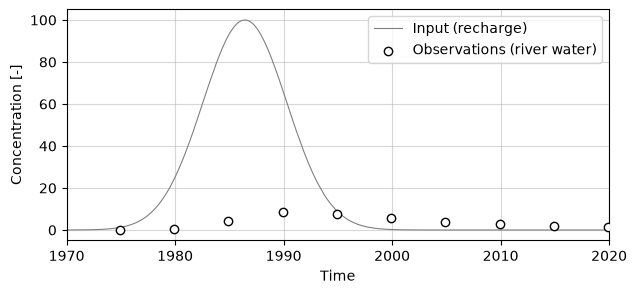

In [2]:
inp = lab.read_series("example_3_input.csv")
obs = lab.read_series("example_3_observations.csv", align_to=inp)
o = obs.values.ravel()
idx = np.where(np.isfinite(o))[0]
t = np.array([d.year + (d.month - 1) / 12 for d in inp.times])
print(len(inp), "monthly time steps,", len(idx), "observations")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t, inp.values.ravel(), c="grey", lw=0.8, label="Input (recharge)")
ax.scatter(t[idx], o[idx], marker="o", facecolor="w", edgecolor="k", zorder=10,
           label="Observations (river water)")
ax.set(xlabel="Time", ylabel="Concentration [-]", xlim=(1970, 2020))
ax.grid(True, alpha=0.5)
ax.legend()
plt.show()

## 2. EM + PM with a Calibrated Mixing Fraction

The model uses monthly time steps (`dt=1/12` yr). Because the tracer input starts in
1970, the steady-state input is 0 (water that recharged before 1970 is tracer-free).
The PM unit with a travel time of 500 yr carries no tracer and represents the
infiltrated water. The fraction of the EM unit is therefore the fraction of
groundwater in river water, not the fraction of young water.

The observations are themselves model output, so there is no measurement error; the
relative uncertainty of 10 % (`sigma_rel=0.1`) stands for the error of the model
structure.

In [3]:
def make_model():
    return lab.Model(
        dt=1 / 12,
        lambda_=lab.decay_constant("Tritium"),
        input_series=inp.values,
        target_series=obs.values,
        steady_state_input=0.0,  # no tracer before 1970
        time_steps=inp.times,
    )


dream_kw = dict(n_samples=2000, burn_in=4000, n_chains=8, cr=[0.25, 0.5, 0.75, 1.0], sigma_rel=0.1,
                return_sim=True, random_state=42)

m_em = make_model()
m_em.add_unit(lab.EMUnit(mtt=10.0), fraction=0.5, prefix="em", bounds=[(0.5, 1000.0)])
m_em.add_unit(lab.PMUnit(mtt=500.0), fraction=0.5, prefix="pm")
m_em.set_fixed("pm.mtt")
m_em.set_fixed("em.fraction", False)
res_em = lab.Solver(m_em).dream_sample(**dream_kw)
print("R-hat:", {k: round(v, 3) for k, v in res_em["gelman_rubin"].items()},
      "| outlier chains moved:", res_em["n_outlier_resets"])
for i, k in enumerate(res_em["param_names"]):
    q = np.quantile(res_em["samples"][:, i], [0.01, 0.5, 0.99])
    print(f"{k:12s} median {q[1]:7.3f}  [1-99 %: {q[0]:.3f}, {q[2]:.3f}]")

R-hat: {'em.fraction': 1.002, 'em.mtt': 1.002} | outlier chains moved: 0
em.fraction  median   0.870  [1-99 %: 0.684, 0.996]
em.mtt       median  58.276  [1-99 %: 43.342, 71.567]


## 3. Age-Bin Model

The age-bin unit divides the travel time axis into bins with fixed edges (here 0, 5,
15, 30, 50, 85 and 1000 yr) and calibrates the weight of each bin; within a bin, the
travel time distribution is uniform. The weights are positive and sum to 1. The last
bin (85-1000 yr) contains old groundwater and the tracer-free infiltrated water, so
that no second unit is needed.

In [4]:
EDGES = [0.0, 5.0, 15.0, 30.0, 50.0, 85.0, 1000.0]
bins = lab.AgeBinUnit(edges=EDGES)
m_bins = make_model()
m_bins.add_unit(bins, fraction=1.0, prefix="bins")
res_bins = lab.Solver(m_bins).dream_sample(**dream_kw)
print("max R-hat:", round(max(res_bins["gelman_rubin"].values()), 3),
      "| outlier chains moved:", res_bins["n_outlier_resets"])
w_bins = bins.weights_from_samples(res_bins, "bins")  # bin weights of every sample
print("Shape of the bin weights:", w_bins.shape)

max R-hat: 1.017 | outlier chains moved: 1
Shape of the bin weights: (16000, 6)


## 4. Comparison with the Groundwater Flow Model

Both models are compared with the true fractions of river water in the travel time
classes: the particle travel times, weighted by the recharge flux, give the travel
time distribution of the groundwater, which makes up 77.9 % of the river water; the
remaining water (old groundwater and the infiltrated water) is in the last class.
For the EM + PM model, the class fractions follow from the EM and the mixing
fraction.

In [5]:
F_RCH = 0.779  # fraction of river water that entered the system via recharge
CLASSES = ["0-5", "5-15", "15-30", "30-50", "50-85", ">85 or\ntracer-free"]

data = np.genfromtxt("example_3_particle_travel_times.csv", delimiter=",", names=True)
tt = data["tts"] / 365.25  # days -> years
wt = data["weights"] / data["weights"].sum()
gw = np.array([wt[(tt >= a) & (tt < b)].sum() for a, b in zip(EDGES[:-2], EDGES[1:-1])])
truth = np.append(F_RCH * gw, 1.0 - F_RCH * gw.sum())

p = res_em["param_names"]
mtt = res_em["samples"][:, p.index("em.mtt")]
frac = res_em["samples"][:, p.index("em.fraction")]
cdf = 1.0 - np.exp(-np.array(EDGES[:-1])[:, None] / mtt)  # EM: exponential distribution
young = frac * np.diff(cdf, axis=0)
w_em = np.vstack([young, 1.0 - young.sum(axis=0)]).T

print(f"{'class [yr]':22s} {'MODFLOW':>8s} {'EM + PM':>8s} {'age bins':>8s}  (medians)")
for c, v, a, b in zip(CLASSES, truth, np.median(w_em, axis=0), np.median(w_bins, axis=0)):
    print(f"{c.replace(chr(10), ' '):22s} {v:8.3f} {a:8.3f} {b:8.3f}")
print(f"{'young water (< 85 yr)':22s} {truth[:5].sum():8.3f} {np.median(w_em[:, :5].sum(axis=1)):8.3f} "
      f"{np.median(w_bins[:, :5].sum(axis=1)):8.3f}")

class [yr]              MODFLOW  EM + PM age bins  (medians)
0-5                       0.074    0.071    0.073
5-15                      0.136    0.126    0.126
15-30                     0.139    0.152    0.153
30-50                     0.089    0.151    0.154
50-85                     0.102    0.166    0.235
>85 or tracer-free        0.459    0.334    0.259
young water (< 85 yr)     0.541    0.666    0.741


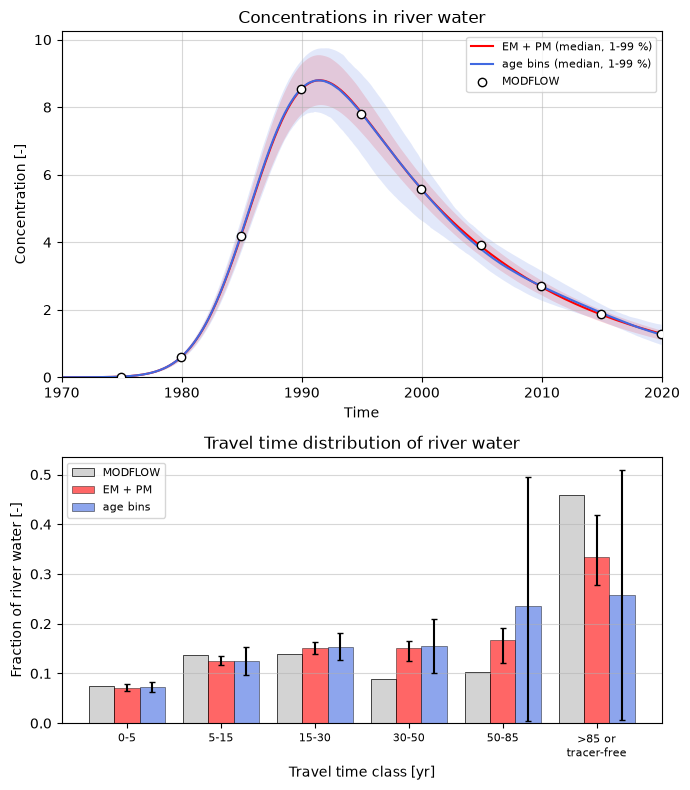

In [6]:
colors = {"EM + PM": "red", "age bins": "royalblue"}
fig, ax = plt.subplots(2, 1, figsize=(7, 8), gridspec_kw={"height_ratios": [1.3, 1]})
for name, res in (("EM + PM", res_em), ("age bins", res_bins)):
    q = np.quantile(res["sims"].reshape(-1, len(o)), [0.01, 0.5, 0.99], axis=0)
    ax[0].fill_between(t, q[0], q[2], color=colors[name], alpha=0.15, lw=0)
    ax[0].plot(t, q[1], c=colors[name], lw=1.5, label=f"{name} (median, 1-99 %)")
ax[0].scatter(t[idx], o[idx], marker="o", facecolor="w", edgecolor="k", zorder=10, label="MODFLOW")
ax[0].set(xlim=(1970, 2020), ylim=(0, None), xlabel="Time", ylabel="Concentration [-]",
          title="Concentrations in river water")
ax[0].grid(True, alpha=0.5)
ax[0].legend(fontsize=8)

x = np.arange(len(CLASSES))
ax[1].bar(x - 0.27, truth, 0.27, color="lightgrey", edgecolor="k", lw=0.5, label="MODFLOW")
for k, (name, sh) in enumerate((("EM + PM", w_em), ("age bins", w_bins))):
    q = np.quantile(sh, [0.01, 0.5, 0.99], axis=0)
    ax[1].bar(x + k * 0.27, q[1], 0.27, color=colors[name], alpha=0.6, edgecolor="k", lw=0.5,
              yerr=[q[1] - q[0], q[2] - q[1]], capsize=2, label=name)
ax[1].set_xticks(x, CLASSES, fontsize=8)
ax[1].set(xlabel="Travel time class [yr]", ylabel="Fraction of river water [-]",
          title="Travel time distribution of river water")
ax[1].grid(True, axis="y", alpha=0.5)
ax[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

Because the tracer input starts in 1970, water older than about 50 yr carries no
tracer in any of the observations: the data cannot distinguish the class 50-85 yr
from the last class, and the uncertainty of these two weights is large. The length
of the tracer record thus limits the part of the travel time distribution that can
be identified.

## Further Reading

- The user guide describes the age-bin unit (choice of the edges, old water) and
  mixing fractions.